# IEEE13 ERCOT report benchmark

This notebook evaluates saved sequential DDPG policies on October 8–9, 2026. Both references use the same measured daily inputs.

Loads are divided by the 2026 archive peak. The report supplies one forecast fallback for missing HE24.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in experiments/ieee13/.")
sys.path.insert(0, str(ROOT / "src"))

from common.workflow import run_experiment
from common.reports import show_training_cost, show_controller_comparison, show_day, show_conclusions

## Parameters

Keep `MODE = "view"` and `OVERWRITE = False` after evaluation. Presentation cells read saved results.

In [2]:
FEEDER = "ieee13"
DATASET = "ieee13-ercotsup"
TRAIN_DATASET = "ieee13-ercot"
SEEDS = [0, 1, 2]
MODE = "view"
OVERWRITE = False
SPLIT = "test"
BETA = 1e-5
SHOW_HOURLY_DETAILS = True

## Saved policies and evaluation

Each policy trains for 7,985 days. Evaluation starts each day at neutral taps and preserves taps between hourly decisions.

Combined cost adds voltage excursion outside [0.95, 1.05] p.u. and beta times executed tap steps.

In [3]:
settings = {
    "protocol": "sequential",
    "feeder": FEEDER,
    "dataset": DATASET,
    "train_dataset": TRAIN_DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": 7985,
    "reward": "band",
    "reward_parameters": {"beta": BETA},
    "beta": BETA,
    "split": SPLIT,
    "evaluation_days": None,
    "run_name": "band_b1e-05",
    "plot_day": 0,
    "show_hourly_details": SHOW_HOURLY_DETAILS,
    "root": ROOT,
}
results = {
    algorithm: run_experiment(settings | {"algorithm": algorithm})
    for algorithm in ("ddpg",)
}

Dataset: ieee13-ercotsup (data/scenarios/ieee13-ercotsup)
Split: test
Evaluated: 2 days, 48 hours
Seeds: [0, 1, 2]
Training days per seed: recorded in saved training records
Switching-cost weight beta: 1e-05
Reward: band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}
Display names and run directories:
  DDPG seed 0: results/ieee13-ercotsup/seq_ddpg/band_b1e-05_seed0/
  DDPG seed 1: results/ieee13-ercotsup/seq_ddpg/band_b1e-05_seed1/
  DDPG seed 2: results/ieee13-ercotsup/seq_ddpg/band_b1e-05_seed2/
  Neutral: results/ieee13-ercotsup/seq_reference/neutral_b1e-05/
  RegControl: results/ieee13-ercotsup/seq_reference/regcontrol_b1e-05/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 2 days, 48 hours, and 5 methods.


## Training records

An episode is one complete 24-decision day. “Training combined cost per day” shows the smoothed seed mean of the fixed evaluation cost on training episodes.

Training includes exploration; these curves are not held-out performance or proof of convergence.

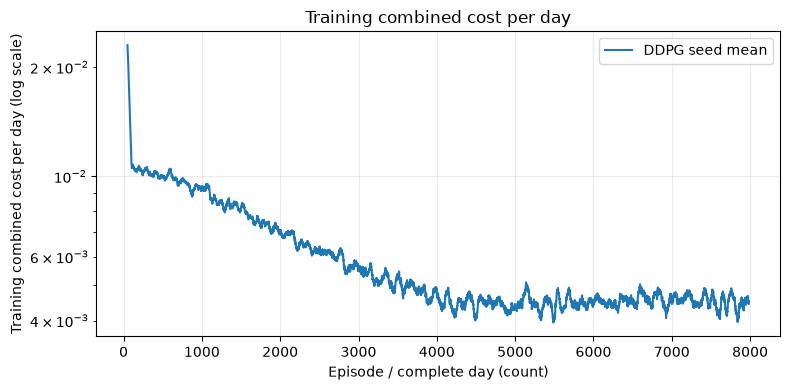

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
for saved in results.values():
    show_training_cost(saved)

## Controller comparison

Tables report common physical costs, tap steps, and hours feasible at [0.95, 1.05] p.u. Each reference evaluates once.

In [5]:
for saved in results.values():
    show_controller_comparison(saved)

Neutral holds every regulator ratio at 1.0. RegControl uses the feeder's native regulator control.

Hourly voltage cost is the mean squared excursion outside [0.95, 1.05] p.u. over 41 monitored line-ground voltage measurements; in-band measurements contribute zero. Daily voltage cost sums 24 hourly costs, and the table averages these daily totals across evaluation days. Lower cost is better. Beta weights tap movement; it is not a monetary price.

Method,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%),Days
DDPG seed 0,7.97882e-05,4.47882e-05,3.50000e-05,2.1186e-02,3.500,62.5,2
DDPG seed 1,8.75480e-05,4.75480e-05,4.00000e-05,2.1071e-02,4.000,62.5,2
DDPG seed 2,6.12784e-05,2.12784e-05,4.00000e-05,2.0763e-02,4.000,62.5,2
Neutral,4.03513e-04,4.03513e-04,0.00000e+00,2.3794e-02,0.000,50.0,2
RegControl,1.90000e-04,0.00000e+00,1.90000e-04,1.3365e-02,19.000,100.0,2


DDPG statistic,Mean daily combined cost,Mean daily voltage cost,Mean daily switching cost,Mean absolute deviation (p.u.),Mean tap steps/day,Feasible hours (%)
Across-seed mean,7.62049e-05,3.78716e-05,3.83333e-05,2.1007e-02,3.833,62.5
Sample standard deviation,1.34964e-05,1.44362e-05,2.88675e-06,2.1900e-04,0.289,0.0


## October 8 hourly behavior

The plots and tables include every hour and both reference controllers.

Selected day: 2026-10-08


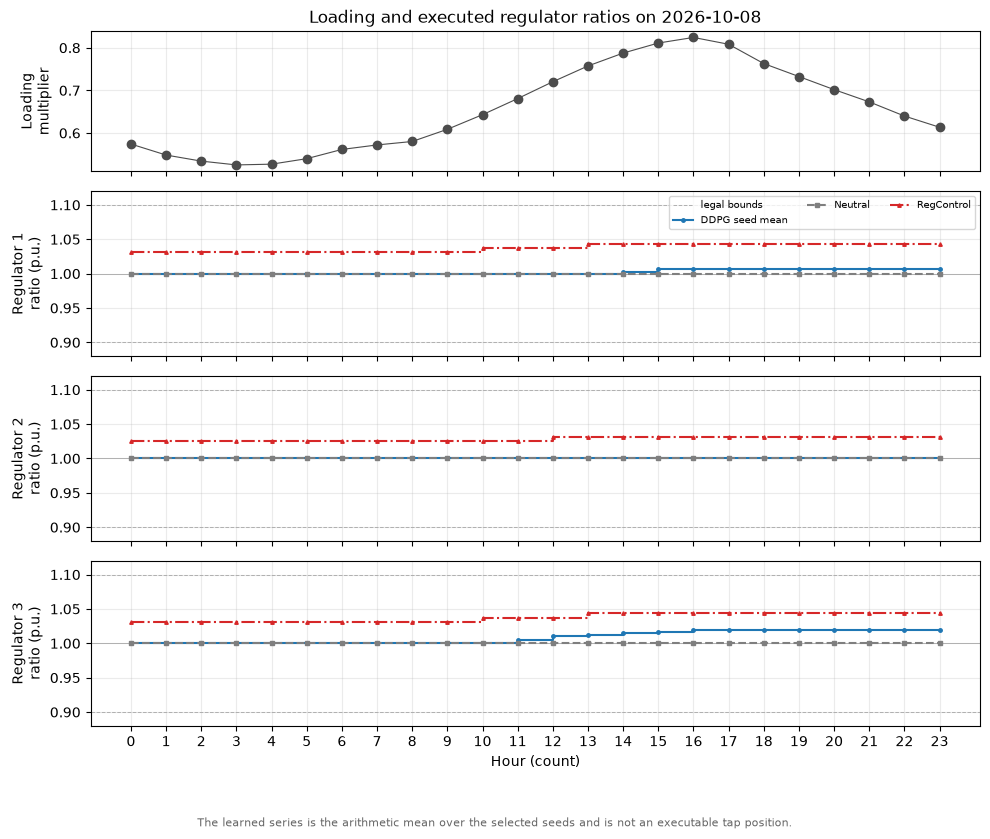

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

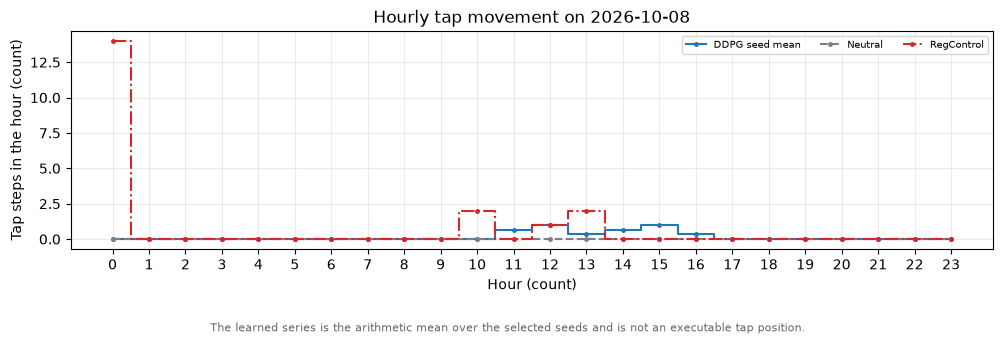

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

Switching cost is tap steps times beta (1e-05).

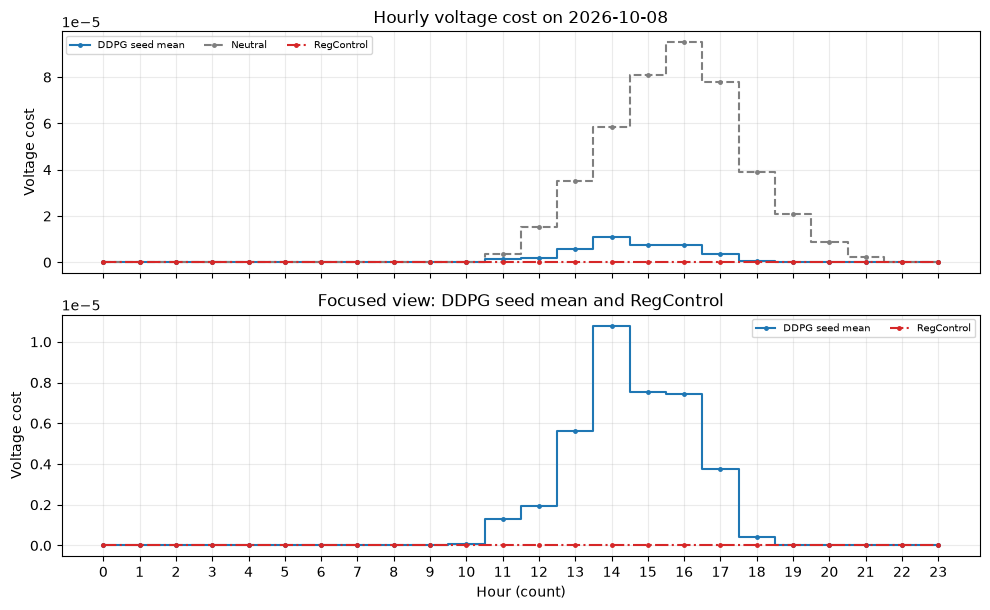

The upper panel keeps every method. The lower panel repeats the controller series without Neutral so their smaller differences remain readable.

Tap indices run from 0 to 32. Convert an index with `ratio = 0.90 + 0.00625 × index`.

Hour,Method,Index 1,Index 2,Index 3,Ratio 1,Ratio 2,Ratio 3,Tap steps,Voltage cost,Switching cost
0,DDPG seed 0,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,DDPG seed 1,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,DDPG seed 2,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,Neutral,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,RegControl,21,20,21,1.03125,1.025,1.03125,14,0.00000e+00,1.40000e-04
1,DDPG seed 0,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,DDPG seed 1,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,DDPG seed 2,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,Neutral,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,RegControl,21,20,21,1.03125,1.025,1.03125,0,0.00000e+00,0.00000e+00


In [6]:
for saved in results.values():
    show_day(saved, 0, SHOW_HOURLY_DETAILS)

## October 9 hourly behavior

HE24 uses the available current-day forecast for its missing actual load.

Selected day: 2026-10-09


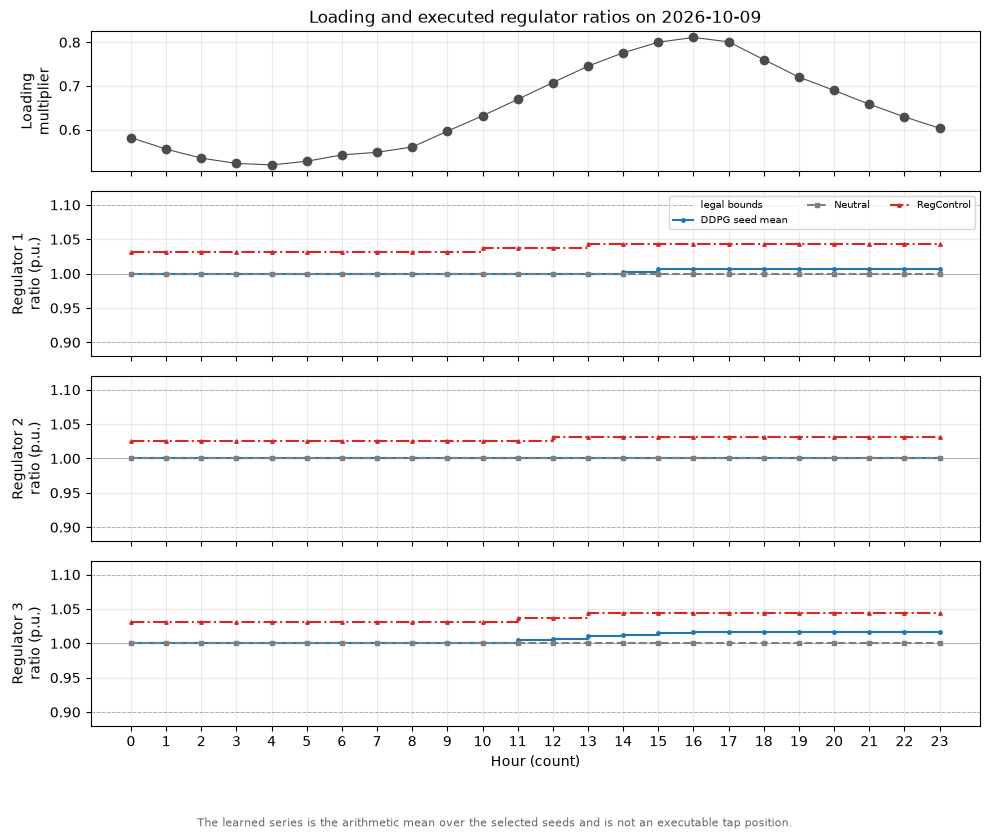

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

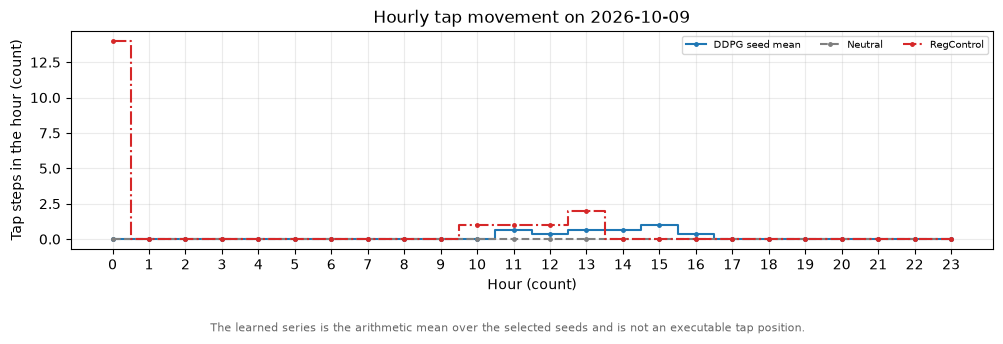

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

Switching cost is tap steps times beta (1e-05).

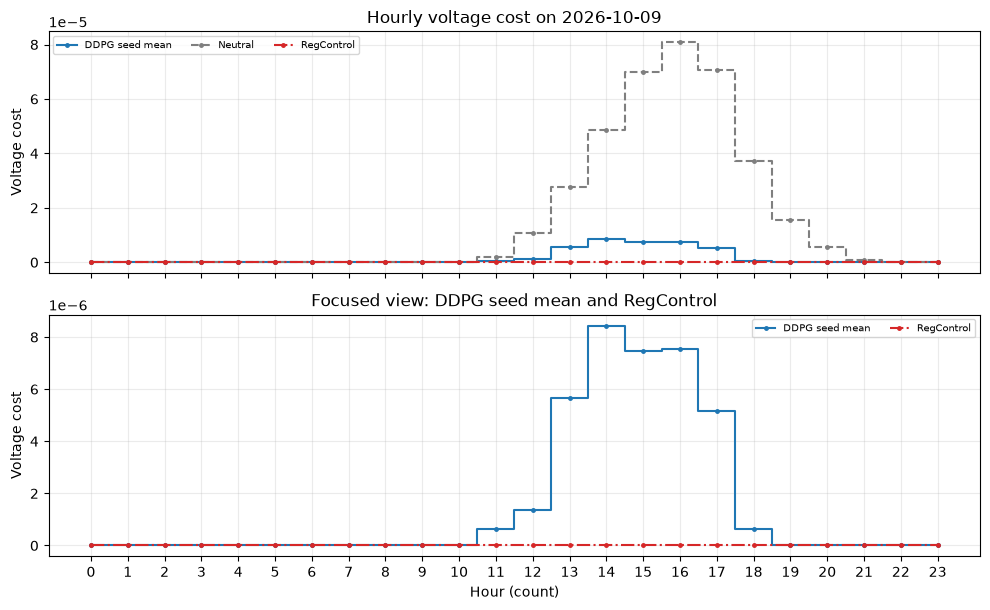

The upper panel keeps every method. The lower panel repeats the controller series without Neutral so their smaller differences remain readable.

Tap indices run from 0 to 32. Convert an index with `ratio = 0.90 + 0.00625 × index`.

Hour,Method,Index 1,Index 2,Index 3,Ratio 1,Ratio 2,Ratio 3,Tap steps,Voltage cost,Switching cost
0,DDPG seed 0,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,DDPG seed 1,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,DDPG seed 2,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,Neutral,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
0,RegControl,21,20,21,1.03125,1.025,1.03125,14,0.00000e+00,1.40000e-04
1,DDPG seed 0,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,DDPG seed 1,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,DDPG seed 2,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,Neutral,16,16,16,1,1,1,0,0.00000e+00,0.00000e+00
1,RegControl,21,20,21,1.03125,1.025,1.03125,0,0.00000e+00,0.00000e+00


In [7]:
for saved in results.values():
    show_day(saved, 1, SHOW_HOURLY_DETAILS)

## Conclusions

The summaries describe these two report days and the recorded training budgets.

In [8]:
for saved in results.values():
    show_conclusions(saved)

The test evaluation covers 2 days for 3 DDPG seeds, beta 1e-05, and 7985 complete training days per seed.

Across 3 independent seeds, DDPG mean daily combined cost is 7.62049e-05 with sample standard deviation 1.34964e-05. This is lower than Neutral (4.03513e-04) and lower than RegControl (1.90000e-04).

DDPG averages voltage cost 3.78716e-05, mean absolute deviation 2.1007e-02 p.u., 3.833 tap steps/day, and 62.5% feasible hours. Neutral uses 0.000 steps/day with voltage cost 4.03513e-04, mean absolute deviation 2.3794e-02 p.u., and 50.0% feasible hours; RegControl uses 19.000 steps/day with voltage cost 0.00000e+00, mean absolute deviation 1.3365e-02 p.u., and 100.0% feasible hours.

Against RegControl, DDPG's voltage cost is higher than RegControl's, its tap steps are lower than RegControl's, and its feasible hours are lower than RegControl's.

These results are limited to the test split, these dataset inputs, and the recorded training budget.